# Denali AC ECM: individual-feature dip estimates

Exploratory workflow kept in `agentic_workspace/dip_angles/`. Uses **cleaned AC only**, with no inter-track signal correlation. Every section gets a figure in `figures/dip_angles/dic1/`, including sections with no accepted features.

Fit depth against lateral track position: $z=a+bx$, using **mm for both coordinates**, then $\theta=\arctan(b)$. Positive angles mean increasing depth with increasing track position. These are **signed apparent dips along the measured face**, not reconstructed 3D dip angles. Depth increases downward in every plot.

Run with the existing **allan_hills_exp** environment. No new packages are required.

In [1]:
from pathlib import Path
import sys
import os
os.environ.setdefault("MPLCONFIGDIR", "/tmp/denali-mpl")
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "scripts/core_scripts/ECMclass.py").exists())
WORK = ROOT / "agentic_workspace/dip_angles"
sys.path.insert(0, str(WORK))
from dip_workflow import Settings, run_all
print("Python:", sys.executable)

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


Python: /Users/Liam/anaconda3/envs/allan_hills_exp/bin/python


## Detection and exclusion rules

1. Preserve all measured tracks. Use their common depth coverage, trim 10 mm at each end, and interpolate to a 0.25 mm grid. Both bracketing raw samples must be finite and have **every flag equal to zero**. Reject gaps exceeding 0.5 mm. Take the union of excluded depths across **all tracks**, including tracks not eventually picked. Thus an entirely flagged track excludes its whole section.
2. Process each uninterrupted clean interval separately. Detect peaks and troughs after Gaussian smoothing with $\sigma=1$ mm. Require prominence greater than both six times the robust first-difference noise estimate and 15% of that track's clean 5th–95th percentile amplitude range. Prominence is local, within 25 mm; feature widths at half-prominence must be 1–15 mm. Broad extrema are intentionally omitted.
3. Keep candidates at least 17.5 mm from any clean-interval boundary, so smoothing and local prominence estimation cannot touch flagged measurements. Require a corresponding extremum within 1 mm at $\sigma=0.75$ and 1.25 mm as a smoothing-stability check.
4. Form same-kind feature hypotheses from distinct-track pairs, bounded by $|\theta|\leq30°$. Match individual extrema within 1.25 mm of the proposed line. Reject ambiguous matches with multiple candidates on any track. Require at least four tracks, with no minimum lateral span or track fraction. Picks must remain in the seed's 30° search cone, allowing one grid step for discretization. All picks must belong to the same globally clean interval.
5. Fit ordinary least squares without removing outliers. Require RMS residual $\leq0.6$ mm, maximum residual $\leq1.2$ mm, leave-one-track-out angle changes $\leq2°$. Require $R^2\geq0.95$, except for nearly flat features with total depth range $\leq1$ mm, where $R^2$ is uninformative.
6. Prefer hypotheses with more tracks, then narrower intervals. Never reuse a pick, and suppress same-kind duplicate features within 5 mm of mean depth. Peaks and troughs from the same waveform can still be statistically dependent.

The 2° interval cutoff and lateral-coverage requirements are disabled; intervals and span remain in the diagnostics. The remaining defaults prioritize a reviewable set. An empty section is **not** evidence of no dipping layers.

In [2]:
cfg = Settings()
SECTIONS = None  # All 16 AC sections, or e.g. ["217abc", "219b"].
# A subset run replaces result tables with that subset; existing figure files remain.
summary, fits = run_all(cfg, sections=SECTIONS)
display(summary)

{'section': '214abcdefg', 'tracks': 10, 'clean_fraction': 0.5340969632392115, 'candidates': 25, 'proposals': 19, 'accepted': 2}


{'section': '216abcdef', 'tracks': 10, 'clean_fraction': 0.43344840813195246, 'candidates': 21, 'proposals': 16, 'accepted': 2}


{'section': '217abc', 'tracks': 10, 'clean_fraction': 0.7900283745439806, 'candidates': 86, 'proposals': 65, 'accepted': 11}


{'section': '219b', 'tracks': 10, 'clean_fraction': 0.985, 'candidates': 40, 'proposals': 26, 'accepted': 5}


{'section': '221abcd', 'tracks': 10, 'clean_fraction': 0.7977443609022556, 'candidates': 0, 'proposals': 0, 'accepted': 0}


{'section': '222a', 'tracks': 11, 'clean_fraction': 0.6668900804289544, 'candidates': 25, 'proposals': 10, 'accepted': 3}


... (7 outputs left out)

{'section': '230a', 'tracks': 10, 'clean_fraction': 1.0, 'candidates': 0, 'proposals': 0, 'accepted': 0}


{'section': '230de', 'tracks': 10, 'clean_fraction': 0.745740498034076, 'candidates': 1, 'proposals': 0, 'accepted': 0}


{'section': '231', 'tracks': 10, 'clean_fraction': 0.7792207792207793, 'candidates': 0, 'proposals': 0, 'accepted': 0}


,section,tracks,clean_fraction,candidates,proposals,accepted
0,214abcdefg,10,0.534097,25,19,2
1,216abcdef,10,0.433448,21,16,2
2,217abc,10,0.790028,86,65,11
3,219b,10,0.985000,40,26,5
4,221abcd,10,0.797744,0,0,0
5,222a,11,0.666890,25,10,3
6,222b,11,0.000000,0,0,0
7,223e,11,0.309278,0,0,0
8,224abc,11,0.818217,7,1,1
9,225cd,11,0.000000,0,0,0


## Fit precision and limitations

The slope standard error uses the larger of residual variance and a pick-error floor. The floor is the larger of 0.25 mm and the largest smoothing-induced candidate shift for that feature. A Student-t interval with $n-2$ degrees of freedom is calculated for the slope, then transformed with arctangent. Tables also report slope, $R^2$, RMS and maximum residuals, lateral span, track count, prominence/noise ratio, and leave-one-out sensitivity.

**These intervals are conditional on the automatically selected picks.** They assume independent track errors and do not account for feature-search selection, mistaken feature identity, correlated measurement errors, instrument alignment, or core orientation. They are not calibrated probabilities that the layer identification is correct. The smoothing check and error floor are practical safeguards, not a measurement-error calibration. No section-level average is inferred from these selected features.

Both point size and color represent interval precision (larger points and smaller colorbar values indicate tighter intervals). Horizontal bars show the conditional 95% interval. Up/down triangles indicate peaks/troughs; numerical labels link each estimate to its picks and fitted line. Gray bands in the right panel show depths excluded across tracks.

The left panel follows `basic_plots`: track strips, Spectral colors, outer-track mean scaling, 10 mm median display smoothing, and raw flag overlays. Detection uses the finer smoothing above on unscaled currents. Display normalization cannot move extrema. The display uses the common trimmed grid and color limits from globally clean data, so it is not pixel-identical to `basic_plots`.

In [3]:
columns = ["section", "feature_id", "kind", "depth_m", "angle_deg", "ci_low_deg", "ci_high_deg",
           "slope_mm_per_mm", "r2", "rmse_mm", "n_tracks", "loo_change_deg"]
if len(fits):
    display(fits[columns].round(4))
else:
    print("No fits passed selection.")

,section,feature_id,kind,depth_m,angle_deg,ci_low_deg,ci_high_deg,slope_mm_per_mm,r2,rmse_mm,n_tracks,loo_change_deg
0,214abcdefg,1,trough,196.9863,-15.7535,-17.5553,-13.9191,-0.2821,0.9819,0.5794,9,0.8006
1,214abcdefg,2,peak,196.9641,-16.9243,-18.6480,-15.1683,-0.3043,0.9958,0.1679,6,0.8204
2,216abcdef,1,trough,198.9269,-7.5515,-8.9617,-6.1321,-0.1326,0.9569,0.4250,9,0.4181
3,216abcdef,2,peak,199.2861,-11.5458,-13.8878,-9.1641,-0.2043,0.9776,0.2643,6,1.1345
4,217abc,1,trough,199.6519,13.7253,12.3448,15.0899,0.2442,0.9890,0.3692,10,0.5802
5,217abc,2,trough,199.9640,-13.6762,-15.6067,-11.7135,-0.2433,0.9733,0.5200,9,1.1915
6,217abc,3,peak,199.7798,12.0372,10.8712,13.1932,0.2132,0.9902,0.2892,8,1.0227
7,217abc,4,peak,199.7148,12.7303,11.1630,14.2783,0.2259,0.9842,0.4580,8,0.6070
8,217abc,5,peak,199.6875,11.9969,10.6590,13.3217,0.2125,0.9928,0.1812,7,0.5296
9,217abc,6,peak,199.8326,9.4291,6.7011,12.1148,0.1661,0.9509,0.3775,7,1.2188


## Review a section

Change `REVIEW_SECTION` to inspect another section. All PNGs are saved regardless of whether they have retained features. Inspect peak identity before using the estimates scientifically; manual picking can be added later without changing the fitting stage.

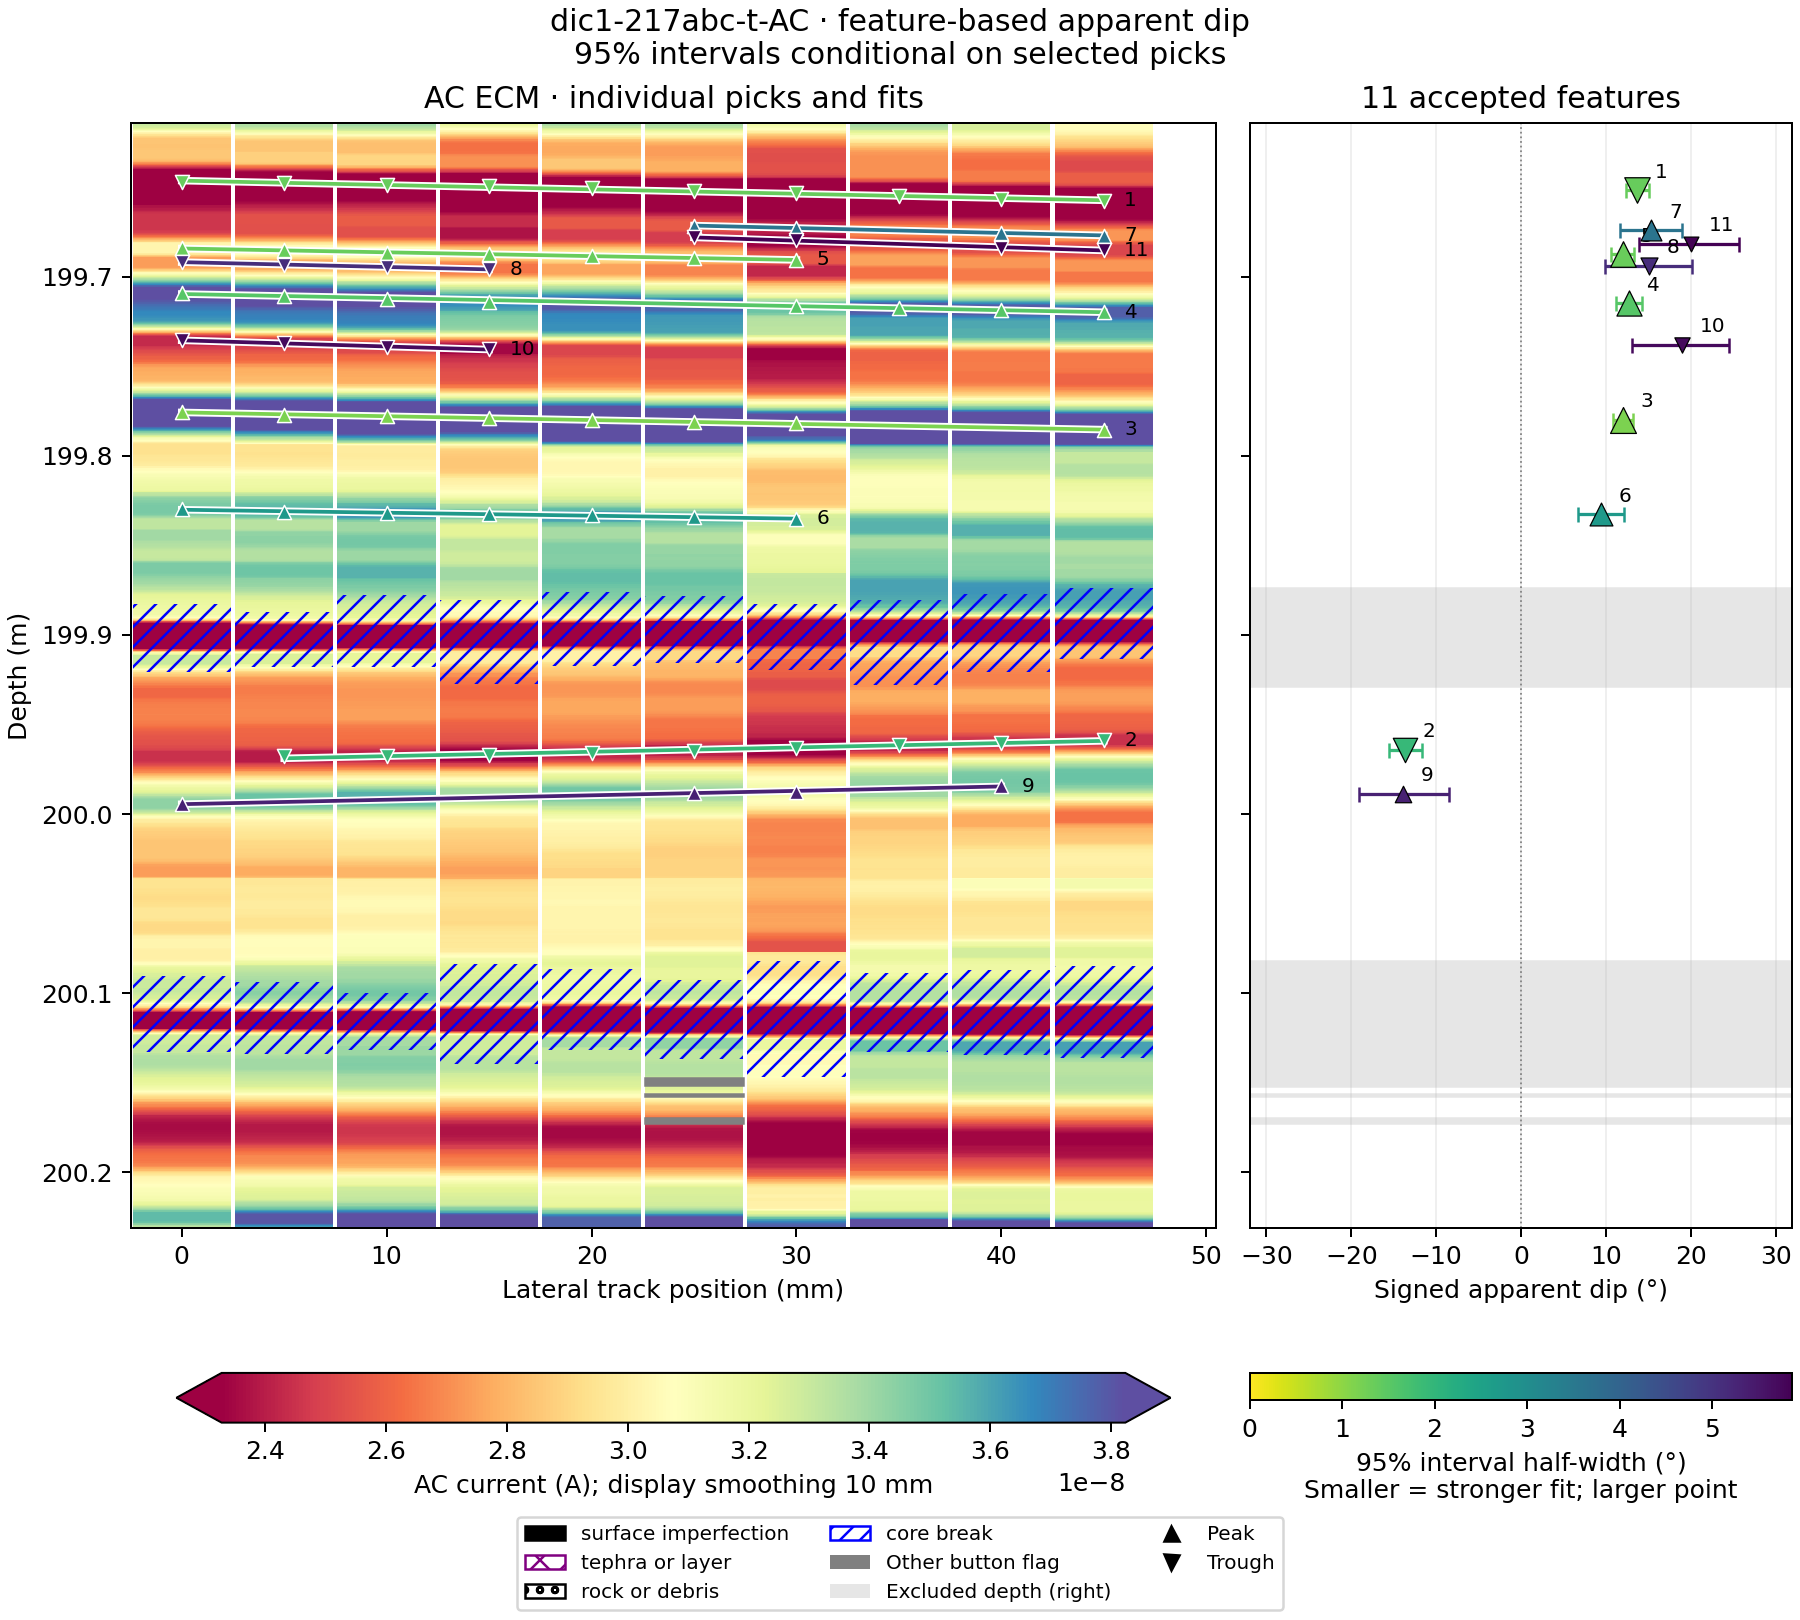

In [4]:
REVIEW_SECTION = "217abc"
display(Image(filename=str(ROOT / f"figures/dip_angles/dic1/dic1-{REVIEW_SECTION}-t-AC-dip.png")))

## Outputs and validation

`results/fits.csv` contains accepted fits, `picks.csv` contains their individual track picks and residuals, and `candidates.csv` contains all extrema passing detection. `proposals.csv` records sufficiently populated, unambiguous hypotheses and their fit rejection/duplicate reasons; it does not enumerate every failed endpoint pair. `section_summary.csv`, `settings.json`, and `input_sha256.json` record coverage, thresholds, and input fingerprints. Candidate IDs are local to each section.

The synthetic checks recover isolated known-angle peaks, including a flat feature, and reject a feature above 30°, a flagged feature, and a feature intersecting a missing-data gap. Real-data checks verify every pick's full detection neighborhood is clean, no picks are reused, and all 16 figures exist. These checks establish implementation behavior, not a real-data false-discovery rate. Run validation after the default full-data run.

In [5]:
if SECTIONS is None:
    from validate_workflow import validate
    display(validate())

{'recovered_-20_deg': -20.059742368057016,
 'recovered_0_deg': 0.0,
 'recovered_15_deg': 14.963831623374245,
 'recovered_29_deg': 29.14297798197175,
 'reject_above_30': True,
 'reject_flagged_feature': True,
 'reject_gap': True,
 'real_picks_clear_of_flags': True,
 'no_reused_picks': True,
 'section_figures': 16,
 'accepted_fits': 27}